# Exploratory data analysis and evaluation setup

**Owner:** Member 1 (Data & Evaluation Lead)  
**Branch:** `m1-data-eval`

## Checklist
- [ ] Load data with memory-saving dtypes
- [ ] Sales over time and seasonality
- [ ] Customer ages and fashion-news status
- [ ] Long tail: how many items sell rarely?
- [ ] Repeat-purchase rate
- [ ] Sales channel (online vs store)
- [ ] Choose and justify the subset window
- [ ] Build and save the time-based split
- [ ] Define segments (new / light / regular) and the new-item set
- [ ] Leakage checklist

> Explain every choice in markdown: what you did, why, and what the result means for the business.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from hm_recsys.data import load_split
from hm_recsys.evaluation import evaluate

In [2]:
train, test = load_split()

print("Training transactions:", len(train))
print("Testing transactions:", len(test))

print("\nTraining period:")
print(train["t_dat"].min(), "to", train["t_dat"].max())

print("\nTesting period:")
print(test["t_dat"].min(), "to", test["t_dat"].max())

print("\nTraining data preview:")
display(train.head())


Training transactions: 3664080
Testing transactions: 240311

Training period:
2020-06-24 00:00:00 to 2020-09-15 00:00:00

Testing period:
2020-09-16 00:00:00 to 2020-09-22 00:00:00

Training data preview:


,t_dat,customer_id,article_id,price,sales_channel_id
0,2020-06-24,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,844409002,0.016932,1
1,2020-06-24,0001b0127d3e5ff8dadcfc6e5043682dba2070f2667081...,876053003,0.025407,1
2,2020-06-24,000493dd9fc463df1acc2081450c9e75ef8e87d5dd17ed...,831269004,0.013542,1
3,2020-06-24,000493dd9fc463df1acc2081450c9e75ef8e87d5dd17ed...,886223001,0.044051,1
4,2020-06-24,000493dd9fc463df1acc2081450c9e75ef8e87d5dd17ed...,868955003,0.019051,1


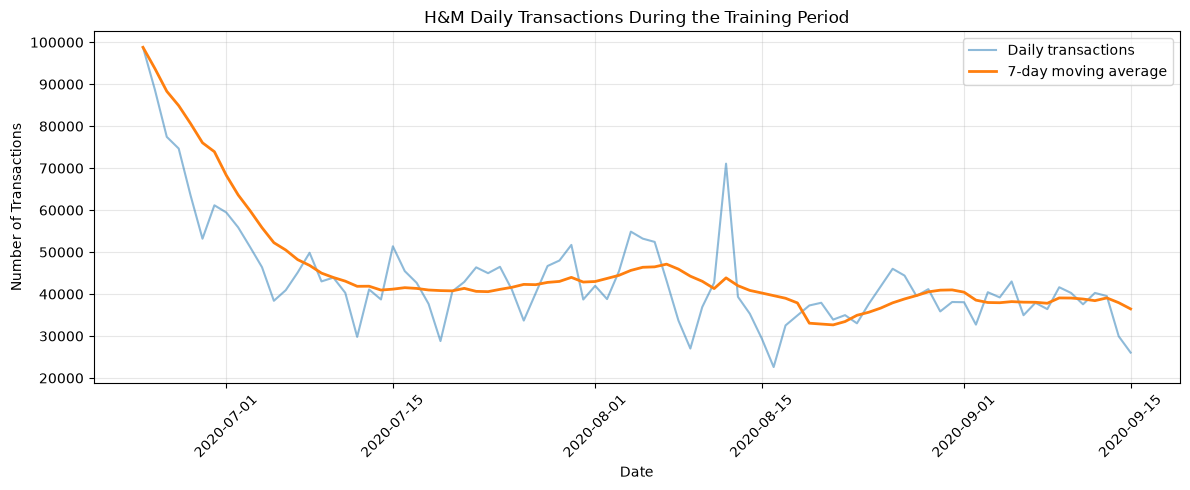

Average daily transactions: 43620
Highest daily transactions: 98790
Lowest daily transactions: 22613
Sales trend check passed!


In [3]:
daily_sales = train.groupby("t_dat").size().sort_index()
rolling_sales = daily_sales.rolling(window=7, min_periods=1).mean()

plt.figure(figsize=(12, 5))

plt.plot(daily_sales.index, daily_sales.values, alpha=0.5, label="Daily transactions")
plt.plot(rolling_sales.index, rolling_sales.values, linewidth=2, label="7-day moving average")

plt.title("H&M Daily Transactions During the Training Period")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Average daily transactions:", round(daily_sales.mean()))
print("Highest daily transactions:", daily_sales.max())
print("Lowest daily transactions:", daily_sales.min())

assert daily_sales.sum() == len(train)
print("Sales trend check passed!")

Daily transactions decreased significantly at the beginning of the training period and became more stable afterwards. 

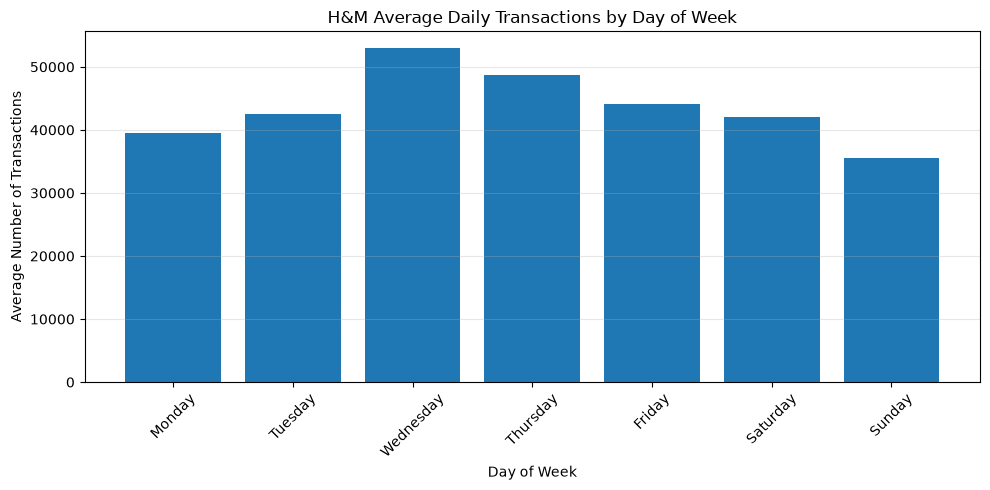

Highest average sales day: Wednesday
Lowest average sales day: Sunday
Weekly seasonality check passed!


In [4]:
weekdays = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = daily_sales.groupby(
    daily_sales.index.day_name()
).mean().reindex(weekdays)

plt.figure(figsize=(10, 5))
plt.bar(weekday_sales.index, weekday_sales.values)

plt.title("H&M Average Daily Transactions by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Number of Transactions")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest average sales day:", weekday_sales.idxmax())
print("Lowest average sales day:", weekday_sales.idxmin())

assert len(weekday_sales) == 7
assert weekday_sales.notna().all()

print("Weekly seasonality check passed!")

Wednesday has the hughest average number of transactions and Sunday had the lowest. 

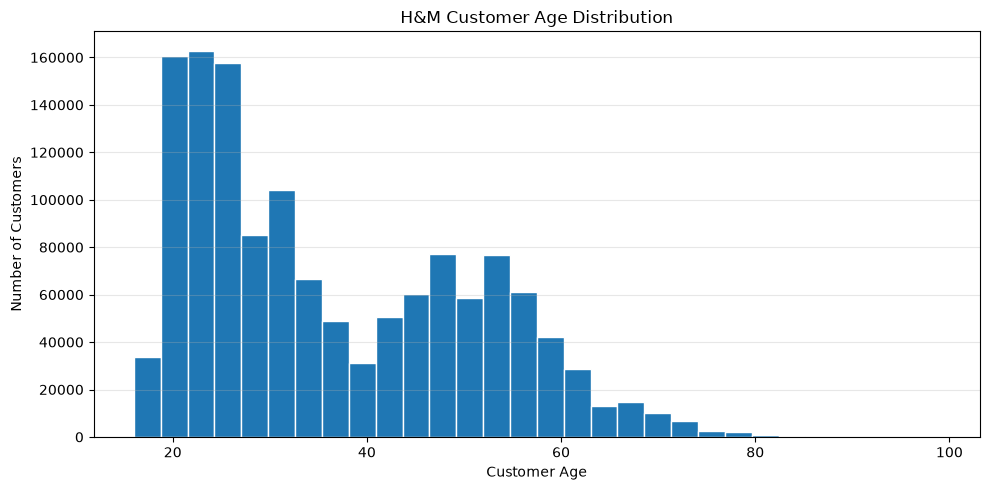

Total customers: 1371980
Average age: 36.4
Median age: 32.0
Missing ages: 15861
Customer age analysis passed!


In [5]:
from hm_recsys.data import RAW_DIR

customers = pd.read_csv(
    RAW_DIR / "customers.csv",
    usecols=["age", "fashion_news_frequency"],
    dtype={
        "age": "float32",
        "fashion_news_frequency": "category"
    }
)

ages = customers["age"].dropna()

plt.figure(figsize=(10, 5))
plt.hist(ages, bins=30, edgecolor="white")

plt.title("H&M Customer Age Distribution")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Total customers:", len(customers))
print("Average age:", round(ages.mean(), 1))
print("Median age:", ages.median())
print("Missing ages:", customers["age"].isna().sum())

assert len(ages) > 0
assert len(ages) + customers["age"].isna().sum() == len(customers)

print("Customer age analysis passed!")

The average customer age was 36.4 years with a median of 32. 

,Customers,Percentage
fashion_news_frequency,,
NONE,877711,64.0
Regularly,477416,34.8
Missing,16011,1.2
Monthly,842,0.1


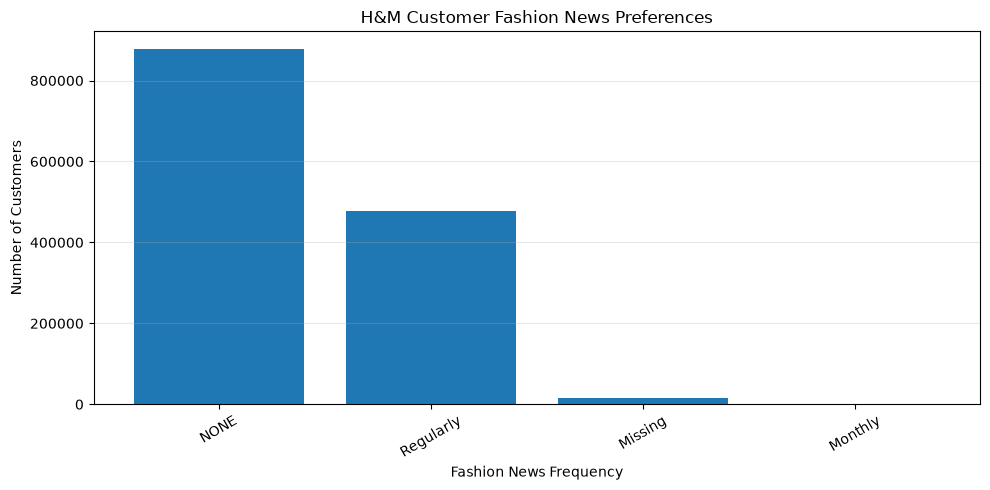

Most common preference: NONE
Total customers: 1371980
Fashion news analysis passed!


In [6]:
news_counts = customers["fashion_news_frequency"].astype("string").fillna("Missing").value_counts()

news_percentages = (news_counts / len(customers) * 100).round(1)

news_summary = pd.DataFrame({
    "Customers": news_counts,
    "Percentage": news_percentages
})

display(news_summary)

plt.figure(figsize=(10, 5))
plt.bar(news_counts.index, news_counts.values)

plt.title("H&M Customer Fashion News Preferences")
plt.xlabel("Fashion News Frequency")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Most common preference:", news_counts.idxmax())
print("Total customers:", news_counts.sum())

assert news_counts.sum() == len(customers)

print("Fashion news analysis passed!")

64% of the customers did not receive fashion news.

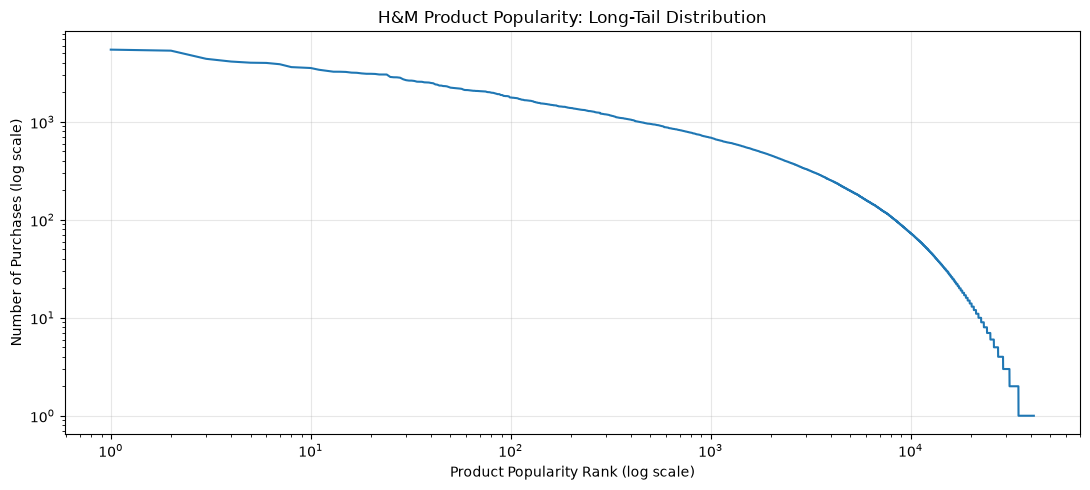

Unique purchased products: 41376
Most purchased product: 706016001
Purchases of most popular product: 5474
Median purchases per product: 13.0
Purchases from top 1% of products: 18.07 %
Products purchased only once: 16.29 %
Product popularity analysis passed!


In [7]:
item_counts = train["article_id"].value_counts().sort_values(ascending=False)

ranks = np.arange(1, len(item_counts) + 1)

plt.figure(figsize=(11, 5))
plt.loglog(ranks, item_counts.values)

plt.title("H&M Product Popularity: Long-Tail Distribution")
plt.xlabel("Product Popularity Rank (log scale)")
plt.ylabel("Number of Purchases (log scale)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

top_n = max(1, int(np.ceil(len(item_counts) * 0.01)))

top_share = item_counts.iloc[:top_n].sum() / len(train) * 100
single_purchase = (item_counts == 1).sum() / len(item_counts) * 100

print("Unique purchased products:", len(item_counts))
print("Most purchased product:", item_counts.index[0])
print("Purchases of most popular product:", item_counts.iloc[0])
print("Median purchases per product:", item_counts.median())
print("Purchases from top 1% of products:", round(top_share, 2), "%")
print("Products purchased only once:", round(single_purchase, 2), "%")

assert item_counts.sum() == len(train)
assert item_counts.index.is_unique
assert 0 <= top_share <= 100

print("Product popularity analysis passed!")

The popularity was not evenly distributed. The top 1% of products accounted for 18.07% of transactions where as 16.29% of products were purchased only once. 

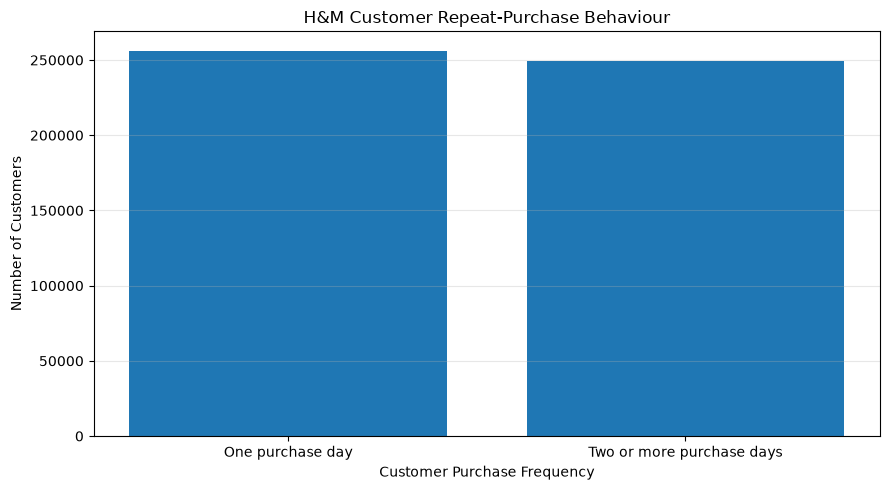

Total purchasing customers: 505310
Customers purchasing on one day: 256266
Repeat customers: 249044
Repeat-purchase rate: 49.29 %
Average purchase days per customer: 2.18
Repeat-purchase analysis passed!


In [8]:
customer_purchase_days = train.groupby(
    "customer_id", observed=True
)["t_dat"].nunique()

one_day_customers = (customer_purchase_days == 1).sum()
repeat_customers = (customer_purchase_days >= 2).sum()

repeat_rate = repeat_customers / len(customer_purchase_days) * 100

plt.figure(figsize=(9, 5))

plt.bar(
    ["One purchase day", "Two or more purchase days"],
    [one_day_customers, repeat_customers]
)

plt.title("H&M Customer Repeat-Purchase Behaviour")
plt.xlabel("Customer Purchase Frequency")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Total purchasing customers:", len(customer_purchase_days))
print("Customers purchasing on one day:", one_day_customers)
print("Repeat customers:", repeat_customers)
print("Repeat-purchase rate:", round(repeat_rate, 2), "%")
print("Average purchase days per customer:", round(customer_purchase_days.mean(), 2))

assert one_day_customers + repeat_customers == len(customer_purchase_days)
assert customer_purchase_days.min() >= 1

print("Repeat-purchase analysis passed!")

49.29% of purchasing customers bought items on more than one day during the trianing period. 

,Transactions,Percentage
sales_channel_id,,
1,1280296,34.94
2,2383784,65.06


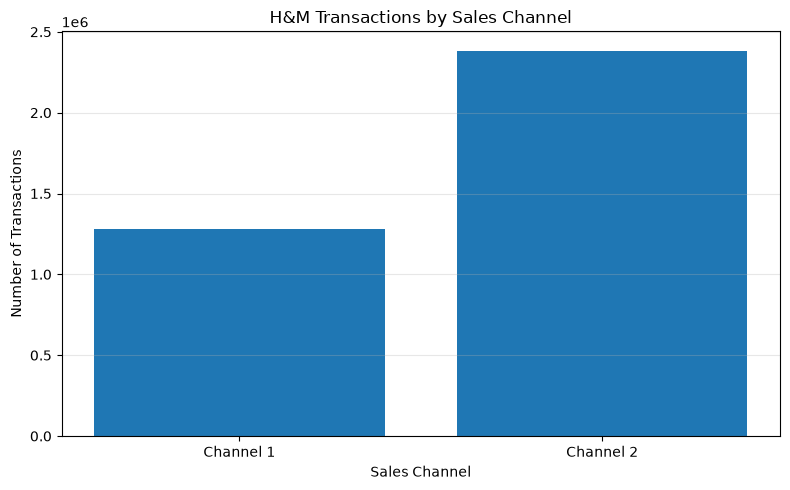

Most used sales channel: 2
Total transactions: 3664080
Sales channel analysis passed!


In [9]:
channel_counts = train["sales_channel_id"].value_counts().reindex([1, 2], fill_value=0)

channel_percentages = (channel_counts / len(train) * 100).round(2)

channel_summary = pd.DataFrame({
    "Transactions": channel_counts,
    "Percentage": channel_percentages
})

display(channel_summary)

plt.figure(figsize=(8, 5))
plt.bar(["Channel 1", "Channel 2"], channel_counts.values)

plt.title("H&M Transactions by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Number of Transactions")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Most used sales channel:", channel_counts.idxmax())
print("Total transactions:", channel_counts.sum())

assert channel_counts.sum() == len(train)
assert set(train["sales_channel_id"].unique()) == {1, 2}

print("Sales channel analysis passed!")

Channel 2 was the dominant sales channel. 

,Customers,Percentage
segment,,
new,19765,28.65
light,16051,23.27
regular,33168,48.08


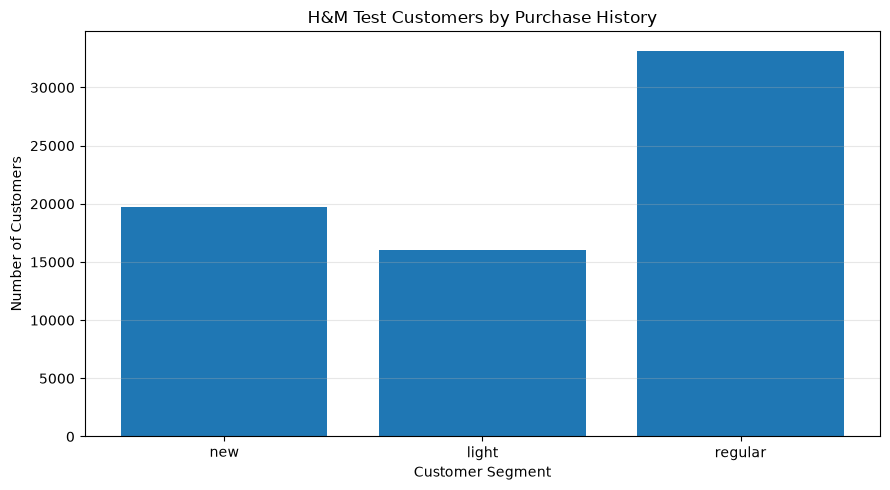

New products in testing: 922
Test transactions involving new products: 9904
New-product transaction percentage: 4.12 %
Customer segmentation and cold-start checks passed!


In [10]:
from hm_recsys.data import assign_segments, new_items

test_customers = test["customer_id"].astype("string").drop_duplicates().reset_index(drop=True)

segments = assign_segments(train, test_customers)

segment_counts = segments.value_counts().reindex(
    ["new", "light", "regular"], fill_value=0
)

segment_percentages = (segment_counts / len(test_customers) * 100).round(2)

segment_summary = pd.DataFrame({
    "Customers": segment_counts,
    "Percentage": segment_percentages
})

display(segment_summary)

plt.figure(figsize=(9, 5))
plt.bar(segment_counts.index, segment_counts.values)

plt.title("H&M Test Customers by Purchase History")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

new_products = new_items(train, test)

new_product_transactions = test["article_id"].isin(new_products).sum()

print("New products in testing:", len(new_products))
print("Test transactions involving new products:", new_product_transactions)
print("New-product transaction percentage:", round(new_product_transactions / len(test) * 100, 2), "%")

assert segment_counts.sum() == len(test_customers)
assert segments.notna().all()
assert new_products.isdisjoint(set(train["article_id"]))

print("Customer segmentation and cold-start checks passed!")

Regular customers represented 48.08% of test customers while 28.65% had no purchases in the training window. 

In [11]:
missing_summary = pd.DataFrame({
    "Training Missing": train.isna().sum(),
    "Training Missing (%)": (train.isna().mean() * 100).round(2),
    "Testing Missing": test.isna().sum(),
    "Testing Missing (%)": (test.isna().mean() * 100).round(2)
})

display(missing_summary)

print("Training period:", train["t_dat"].min(), "to", train["t_dat"].max())
print("Testing period:", test["t_dat"].min(), "to", test["t_dat"].max())

assert train["t_dat"].max() < test["t_dat"].min()
assert len(train) == 3664080
assert len(test) == 240311

assert train["customer_id"].notna().all()
assert test["customer_id"].notna().all()

assert train["article_id"].notna().all()
assert test["article_id"].notna().all()

assert new_products == (
    set(test["article_id"]) - set(train["article_id"])
)

print("Missing customer and article IDs: None")
print("Training and testing dates do not overlap")
print("New-product identification: Correct")
print("Data quality and temporal leakage checks passed!")

,Training Missing,Training Missing (%),Testing Missing,Testing Missing (%)
t_dat,0,0.0,0,0.0
customer_id,0,0.0,0,0.0
article_id,0,0.0,0,0.0
price,0,0.0,0,0.0
sales_channel_id,0,0.0,0,0.0


Training period: 2020-06-24 00:00:00 to 2020-09-15 00:00:00
Testing period: 2020-09-16 00:00:00 to 2020-09-22 00:00:00
Missing customer and article IDs: None
Training and testing dates do not overlap
New-product identification: Correct
Data quality and temporal leakage checks passed!


In [12]:
train_days = (train["t_dat"].max() - train["t_dat"].min()).days + 1
test_days = (test["t_dat"].max() - test["t_dat"].min()).days + 1

total_days = train_days + test_days

print("Training days:", train_days)
print("Testing days:", test_days)
print("Total days:", total_days)
print("Training transactions:", len(train))
print("Testing transactions:", len(test))

assert train_days == 84
assert test_days == 7
assert total_days == 91
assert train["t_dat"].max() + pd.Timedelta(days=1) == test["t_dat"].min()

print("Training window validation passed!")

Training days: 84
Testing days: 7
Total days: 91
Training transactions: 3664080
Testing transactions: 240311
Training window validation passed!


We used 12 weeks of training data and one week for testing. No missing values were found. 